In [51]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

In [52]:
torch.manual_seed(0)

data definition

In [53]:
# Points in a square. Class 1 if the point is inside a circle, class 0 if it is outside.
#  A straight line cannot separate this, so it needs a nonlinear mode
def data_maker(n):
    x = torch.rand(n, 2) * 2 - 1
    y = (x[:, 0]**2 + x[:, 1]**2 < 0.5).long()
    x = x + 0.05 * torch.randn(n, 2)
    return x, y

In [54]:
class classifier(nn.Module):
    def __init__(self, hidden=16):
        super().__init__()
        self.layer = nn.Sequential(
            nn.Linear(2, hidden), nn.Tanh(),
            nn.Linear(hidden,hidden), nn.Tanh(),
            nn.Linear(hidden, 2)
        
        )
    def forward(self, x):
        return self.layer(x)
    


In [ ]:
def accuracy(model, x, y):
        with torch.no_grad():
            return(model(x).argmax(dim=1)==y).float().mean().item()
# The argmax for each row gives the index of the larger score; if it is equal to y, then the prediction is true

In [ ]:
x_train, y_train = data_maker(10000)
x_test, y_test = data_maker(7000)
train_loader =DataLoader(TensorDataset(x_train, y_train), batch_size=32, shuffle=True)
# TensorDataset(x_train, y_train) pairs each point with its label.
# DataLoader(..., batch_size=32, shuffle=True) hands out the data in groups of 32, in random order, and reshuffles every epoch

In [ ]:
model = classifier()
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

In [58]:
for epoch in range(30):
    for xb, yb in train_loader:
        loss = loss_fn(model(x_train),y_train)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    if epoch % 5==0:
        print(epoch, round(loss.item(), 4), round(accuracy(model, x_train, y_train), 3),
              round(accuracy(model, x_test, y_test), 3))

0 0.0969 0.957 0.954
5 0.0953 0.958 0.955
10 0.0943 0.958 0.954
15 0.0929 0.958 0.954
20 0.0906 0.959 0.953
25 0.0887 0.959 0.951


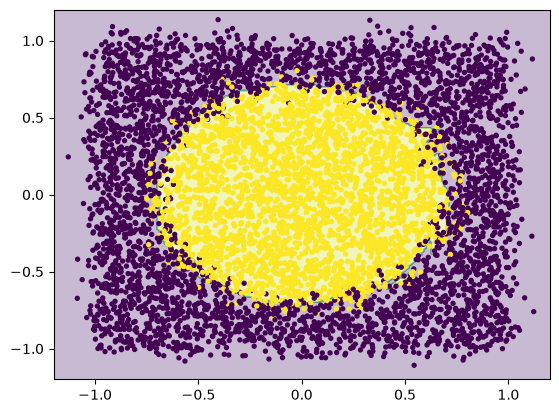

In [59]:
import matplotlib.pyplot as plt
g = torch.linspace(-1.2, 1.2, 200)
gx, gy = torch.meshgrid(g, g, indexing="xy")
grid = torch.stack([gx.flatten(), gy.flatten()], dim=1)
with torch.no_grad():
    pred = model(grid).argmax(dim=1).reshape(200, 200)
plt.contourf(gx.numpy(), gy.numpy(), pred.numpy(), alpha=0.3)
plt.scatter(x_test[:, 0], x_test[:, 1], c=y_test.numpy(), s=8)
plt.show()

In [63]:
model2 = nn.Linear(2,2)
loss_fn2 = nn.CrossEntropyLoss()
optimizer2 = torch.optim.Adam(model.parameters(), lr=0.01)

In [64]:
for epoch in range(30):
    for xb, yb in train_loader:
        loss2 = loss_fn2(model2(x_train),y_train)
        optimizer2.zero_grad()
        loss2.backward()
        optimizer2.step()
    if epoch % 5==0:
        print(epoch, round(loss2.item(), 4), round(accuracy(model2, x_train, y_train), 3),
              round(accuracy(model2, x_test, y_test), 3))

0 0.7079 0.475 0.482
5 0.7079 0.475 0.482
10 0.7079 0.475 0.482
15 0.7079 0.475 0.482
20 0.7079 0.475 0.482
25 0.7079 0.475 0.482


In [ ]:
model = classifier()
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

In [68]:
x_train2, y_train2 = data_maker(10000)
x_test2, y_test2 = data_maker(7000)
train_loader2 =DataLoader(TensorDataset(x_train2, y_train2), batch_size=16, shuffle=True)

In [69]:
model3 = classifier()
loss_fn3 = nn.CrossEntropyLoss()
optimizer3 = torch.optim.Adam(model.parameters(), lr=0.01)

In [70]:
for epoch in range(30):
    for xb, yb in train_loader:
        loss3 = loss_fn3(model2(x_train2),y_train2)
        optimizer3.zero_grad()
        loss3.backward()
        optimizer3.step()
    if epoch % 5==0:
        print(epoch, round(loss3.item(), 4), round(accuracy(model3, x_train2, y_train2), 3),
              round(accuracy(model3, x_test2, y_test2), 3))

0 0.7062 0.383 0.392
5 0.7062 0.383 0.392
10 0.7062 0.383 0.392
15 0.7062 0.383 0.392
20 0.7062 0.383 0.392
25 0.7062 0.383 0.392
